# 1b — Costa Rica Network Preparation

Prepare the modified cantonal road network as a directed, AADT-attributed, strongly connected routing network for the Costa Rica criticality workflow.

## Input

| File | Description |
|---|---|
| `input_files/CR_RED_TOPOGRAFICA/cr_red_topografica.shp` | Modified cantonal road network in CR-SIRGAS / CRTM05 (EPSG:8908), including `T9`–`T15`, `DIRECCION`, and `VEL_KMH` |

## Outputs

| File | Description |
|---|---|
| `intermediate_results/gpkg/network/main_network_directed.gpkg` | Strongly connected directed road network |
| `intermediate_results/gpkg/network/giant_component_dropped_roads.gpkg` | Directed edges outside the strong giant component |
| `intermediate_results/gpkg/network/endpoint_snap_log.csv` | Auditable endpoint-snap log |
| `figures/{traffic_type}_aadt_map.png` | Seven individual AADT maps |
| `figures/AADT_categories_combined.png` | Seven-panel AADT overview |
| `figures/oneway_direction_qa.png` | Digitized direction of one-way roads |
| `figures/giant_component_dropped_roads.png` | Included versus dropped physical roads |

## Processing steps

- Load the modified cantonal road network and validate its schema, CRS, and geometries.
- Remove exact duplicates and explode multipart roads into traceable LineStrings.
- Snap endpoints to nearby endpoints or road segments using a 2 m tolerance and 30 m search buffer.
- Split roads at valid intersections and construct integer `from_id` / `to_id` topology.
- Fill missing `T9`–`T15` AADT values using endpoint neighbours, road-class medians, and a global fallback.
- Create descriptive traffic fields and calculate `total_aadt`.
- Generate seven individual AADT maps and the combined AADT figure.
- Normalize `DIRECCION`, halve two-way AADT, and create reverse copies of bidirectional roads.
- Preserve supplied speeds, fill missing speeds, and calculate road length and free-flow travel time.
- Build the directed graph and extract its strongly connected giant component.
- Save dropped-road diagnostics before enforcing the 95% physical-length threshold.
- Write and reopen the final GeoPackages to validate their CRS, schema, IDs, and critical values.

## Methodological decisions

- Zero AADT is observed data; only null values are imputed.
- Missing AADT is filled independently for `T9`–`T15`: endpoint-neighbour mean first, then `CLASE` median with a global fallback and touching-road cap.
- Missing `DIRECCION` is treated as bidirectional and retained in `direction_imputed`. One-way travel follows source digitization.
- Bidirectional AADT is divided by two before the reverse edge is appended.
- Supplied `VEL_KMH` is preserved. Missing speeds use the `CLASE` median and finally the 60 km/h unsigned-road fallback in [Costa Rica Traffic Law 9078, Article 98](https://pgrweb.go.cr/scij/Busqueda/Normativa/Normas/nrm_articulo.aspx?nValor1=1&nValor2=73504&nValor3=125198&nValor5=99&param1=NRA&strTipM=FA).
- `road_length` is derived from projected geometry; `fft = road_length / speed` is expressed in hours.
- The final strong component must retain at least 95% of unique physical network length. Diagnostic outputs are saved before this assertion.


In [1]:
from pathlib import Path
import sys

PROJECT_CANDIDATE = Path.cwd().resolve()
BASE_DIR = PROJECT_CANDIDATE.parent if PROJECT_CANDIDATE.name == 'notebooks' else PROJECT_CANDIDATE
if not (BASE_DIR / 'input_files').exists():
    raise FileNotFoundError(f'Could not resolve project root from {Path.cwd()}')
if str(BASE_DIR) not in sys.path:
    sys.path.insert(0, str(BASE_DIR))

from src.network_preparation_cr import (
    AADT_ALIASES,
    AADT_COLUMNS,
    CRNetworkPrepConfig,
    add_speed_and_travel_time,
    build_topology,
    create_directed_edges,
    extract_strong_giant_component,
    fill_missing_aadt,
    load_and_validate_network,
    plot_aadt_maps,
    plot_direction_qa,
    save_outputs,
    snap_network_iteratively,
)


In [2]:
config = CRNetworkPrepConfig(
    base_dir=BASE_DIR,
    snap_tolerance_m=2.0,
    snap_search_buffer_m=30.0,
    snap_max_iterations=20,
    min_giant_component_length_pct=95.0,
    statutory_default_speed_kmh=60.0,
    add_basemap=True,
)
config.ensure_output_dirs()
print(f'Input: {config.input_path}')
print(f'GeoPackage outputs: {config.gpkg_dir}')
print(f'Figures: {config.figure_path}')


Input: /Users/joeldeplaen/Library/CloudStorage/OneDrive-VrijeUniversiteitAmsterdam/Documents/GitHub/Criticality-Analysis-CR/input_files/CR_RED_TOPOGRAFICA/cr_red_topografica.shp
GeoPackage outputs: /Users/joeldeplaen/Library/CloudStorage/OneDrive-VrijeUniversiteitAmsterdam/Documents/GitHub/Criticality-Analysis-CR/intermediate_results/gpkg/network
Figures: /Users/joeldeplaen/Library/CloudStorage/OneDrive-VrijeUniversiteitAmsterdam/Documents/GitHub/Criticality-Analysis-CR/figures


## 1. Load, validate, deduplicate, and explode multipart roads

The loader enforces the CR schema and EPSG:8908, rejects invalid geometry, preserves source IDs, and explodes multipart features into traceable LineStrings.


In [3]:
roads, load_stats = load_and_validate_network(config)
display(roads.head())
load_stats


CR source validation
  source features       : 4,764
  deduplicated features : 4,764
  multipart features    : 130
  exploded LineStrings  : 4,910
  exact duplicates      : 0
  working CRS           : EPSG:8908
  DIRECCION values:
DIRECCION
Bidireccional     4542
Unidireccional     247
None               121
  VEL_KMH values:
VEL_KMH
20.0       2
40.0    4349
60.0     260
80.0     159
NaN      140
  AADT completeness:
T9     62.5%
T10    62.5%
T11    62.5%
T12    62.5%
T13    62.5%
T14    62.4%
T15    62.5%


,source_row_id,ID_TRAMO,TRAMO_UID,ID_RUTA,NOMBRE,ADMIN,CLASE,LONGITUD,ANCHO,SUPERFICIE,...,vul_eq,rep_cost_k,VEL_KMH,NODO_INI,NODO_FIN,COD_CAMI_1,Cod_camino,geometry,source_part_no,source_part_id
0,0,1.0,1.0,39.0,Ruta Nacional No. 39,Estado,Primaria,444.357626,17.5,S,...,None,1211648.29,80.0,2042.0,2092.0,None,NaN,"LINESTRING (491796.817 1096163.21, 491794.168 ...",0,0:0
1,1,2.0,2.0,32.0,Ruta Nacional No. 32,Estado,Primaria,325.505186,8.1,S,...,None,1211648.29,80.0,2043.0,3453.0,None,NaN,"LINESTRING (553686.296 1116252.638, 553716.739...",0,1:0
2,2,3.0,3.0,1.0,Ruta Nacional No. 1,Estado,Primaria,143.596631,18.8,S,...,None,1211648.29,40.0,2510.0,2103.0,None,NaN,"LINESTRING (489228.773 1098737.797, 489226.789...",0,2:0
3,3,4.0,4.0,1.0,Ruta Nacional No. 1,Estado,Primaria,674.908007,19.7,S,...,None,1211648.29,80.0,2540.0,2178.0,None,NaN,"LINESTRING (487754.779 1100227.592, 487737.668...",0,3:0
4,4,5.0,5.0,1.0,Ruta Nacional No. 1,Estado,Primaria,1180.511257,19.0,S,...,None,1211648.29,80.0,2122.0,2045.0,None,NaN,"LINESTRING (478578.056 1105762.449, 478567.074...",0,4:0


{'source_crs': 'EPSG:8908',
 'working_crs': 'EPSG:8908',
 'source_features': 4764,
 'deduplicated_features': 4764,
 'multipart_features': 130,
 'exploded_lines': 4910,
 'exact_duplicates_removed': 0,
 'length_ratio_summary': {'min': 0.04265152411413563,
  'median': 1.0000896238451955,
  'max': 344439.328113888}}

## 2. Snap endpoints iteratively

Endpoints are moved to the nearest road endpoint or segment only when the distance is greater than zero and at most 2 m. Each endpoint is snapped at most once, the spatial index is rebuilt per iteration, and all changes are logged.


In [4]:
snapped_roads, snap_log = snap_network_iteratively(
    roads,
    tolerance_m=config.snap_tolerance_m,
    search_buffer_m=config.snap_search_buffer_m,
    max_iterations=config.snap_max_iterations,
)
snap_log_path = config.gpkg_dir / 'endpoint_snap_log.csv'
snap_log.to_csv(snap_log_path, index=False)
print(f'Saved snap log: {snap_log_path}')
display(snap_log.head())


Snap iteration 1: 626 endpoint changes
Snap iteration 2: 0 endpoint changes
Total endpoint snaps: 626
Saved snap log: /Users/joeldeplaen/Library/CloudStorage/OneDrive-VrijeUniversiteitAmsterdam/Documents/GitHub/Criticality-Analysis-CR/intermediate_results/gpkg/network/endpoint_snap_log.csv


,iteration,edge_index,source_part_id,endpoint,target_edge_index,target_source_part_id,snap_distance_m
0,1,3,3:0,start,3582,3502:0,1.199982e-09
1,1,18,18:0,end,739,737:0,2.606931e-02
2,1,23,23:0,end,3517,3454:0,2.095476e-09
3,1,26,26:0,end,2998,2970:0,5.549050e-03
4,1,27,27:0,start,2964,2936:0,1.285440e-02


## 3. Split intersections and build topology

All geometry edits occur before this step. Intersection parts retain source identifiers, receive a unique `physical_edge_id`, and are linked through integer `from_id` / `to_id` nodes.


In [5]:
physical_edges, network_nodes, topology_stats = build_topology(snapped_roads)
display(physical_edges.head())
topology_stats


Topology summary
  input_edges           : 4,910
  topology_edges        : 5,090
  nodes                 : 4,030
  new_split_edges       : 180
  intersection_pairs    : 7,583
  overlap_pairs         : 30
  self_loops            : 0
  weak_components       : 48


,source_row_id,ID_TRAMO,TRAMO_UID,ID_RUTA,NOMBRE,ADMIN,CLASE,LONGITUD,ANCHO,SUPERFICIE,...,COD_CAMI_1,Cod_camino,source_part_no,source_part_id,topology_part_no,geometry,physical_edge_id,from_id,to_id,id
0,0,1.0,1.0,39.0,Ruta Nacional No. 39,Estado,Primaria,444.357626,17.5,S,...,None,NaN,0,0:0,0,"LINESTRING (491796.817 1096163.21, 491794.168 ...",0,0,1,0
1,1,2.0,2.0,32.0,Ruta Nacional No. 32,Estado,Primaria,325.505186,8.1,S,...,None,NaN,0,1:0,0,"LINESTRING (553686.296 1116252.638, 553716.739...",1,2,3,1
2,2,3.0,3.0,1.0,Ruta Nacional No. 1,Estado,Primaria,143.596631,18.8,S,...,None,NaN,0,2:0,0,"LINESTRING (489228.773 1098737.797, 489226.789...",2,4,5,2
3,3,4.0,4.0,1.0,Ruta Nacional No. 1,Estado,Primaria,674.908007,19.7,S,...,None,NaN,0,3:0,0,"LINESTRING (487754.779 1100227.592, 487737.668...",3,6,7,3
4,4,5.0,5.0,1.0,Ruta Nacional No. 1,Estado,Primaria,1180.511257,19.0,S,...,None,NaN,0,4:0,0,"LINESTRING (478578.056 1105762.449, 478567.074...",4,8,9,4


{'input_edges': 4910,
 'topology_edges': 5090,
 'nodes': 4030,
 'new_split_edges': 180,
 'intersection_pairs': 7583,
 'overlap_pairs': 30,
 'self_loops': 0,
 'weak_components': 48}

## 4. Fill the existing CR AADT fields

No separate AADT merge is needed. Missing values are filled category-by-category, while source/fill provenance remains in the edge table.


In [6]:
physical_edges, aadt_completeness, aadt_fill_sources = fill_missing_aadt(physical_edges)
display(aadt_completeness.round(1))
display(aadt_fill_sources)


AADT completeness before/after imputation
category  complete_before  complete_after  total_edges  pct_before  pct_after
      T9             3178            5090         5090        62.4      100.0
     T10             3178            5090         5090        62.4      100.0
     T11             3178            5090         5090        62.4      100.0
     T12             3175            5090         5090        62.4      100.0
     T13             3174            5090         5090        62.4      100.0
     T14             3167            5090         5090        62.2      100.0
     T15             3177            5090         5090        62.4      100.0
AADT fill sources
category   fill_source  edges
      T9      observed   3178
      T9  class_median   1600
      T9 endpoint_mean    220
      T9 global_median     92
     T10      observed   3178
     T10  class_median   1600
     T10 endpoint_mean    220
     T10 global_median     92
     T11      observed   3178
     T11  class_

,category,complete_before,complete_after,total_edges,pct_before,pct_after
0,T9,3178,5090,5090,62.4,100.0
1,T10,3178,5090,5090,62.4,100.0
2,T11,3178,5090,5090,62.4,100.0
3,T12,3175,5090,5090,62.4,100.0
4,T13,3174,5090,5090,62.4,100.0
5,T14,3167,5090,5090,62.2,100.0
6,T15,3177,5090,5090,62.4,100.0


,category,fill_source,edges
0,T9,observed,3178
1,T9,class_median,1600
2,T9,endpoint_mean,220
3,T9,global_median,92
4,T10,observed,3178
5,T10,class_median,1600
6,T10,endpoint_mean,220
7,T10,global_median,92
8,T11,observed,3178
9,T11,class_median,1600


## 5. Visualise all seven AADT categories

Figures use the physical network before direction duplication. Category breaks are data-driven and printed for reproducibility. Basemap failures are non-fatal.


motorcycles AADT breaks: [0.0, 516.0, 1275.7000000000007, 2311.0, 3532.0, 19925.0]
pickup_trucks AADT breaks: [1.0, 1107.0, 1288.0, 2382.4000000000033, 7465.0, 97095.0]
passenger_cars AADT breaks: [0.0, 49.0, 141.0, 265.0, 4934.0]
buses AADT breaks: [0.0, 131.0, 361.0, 640.2000000000003, 8540.0]
light_trucks AADT breaks: [0.0, 16.0, 56.0, 117.0, 1724.0]
medium_trucks AADT breaks: [0.0, 23.0, 971.0]
heavy_trucks AADT breaks: [0.0, 17.0, 92.0, 4252.0]


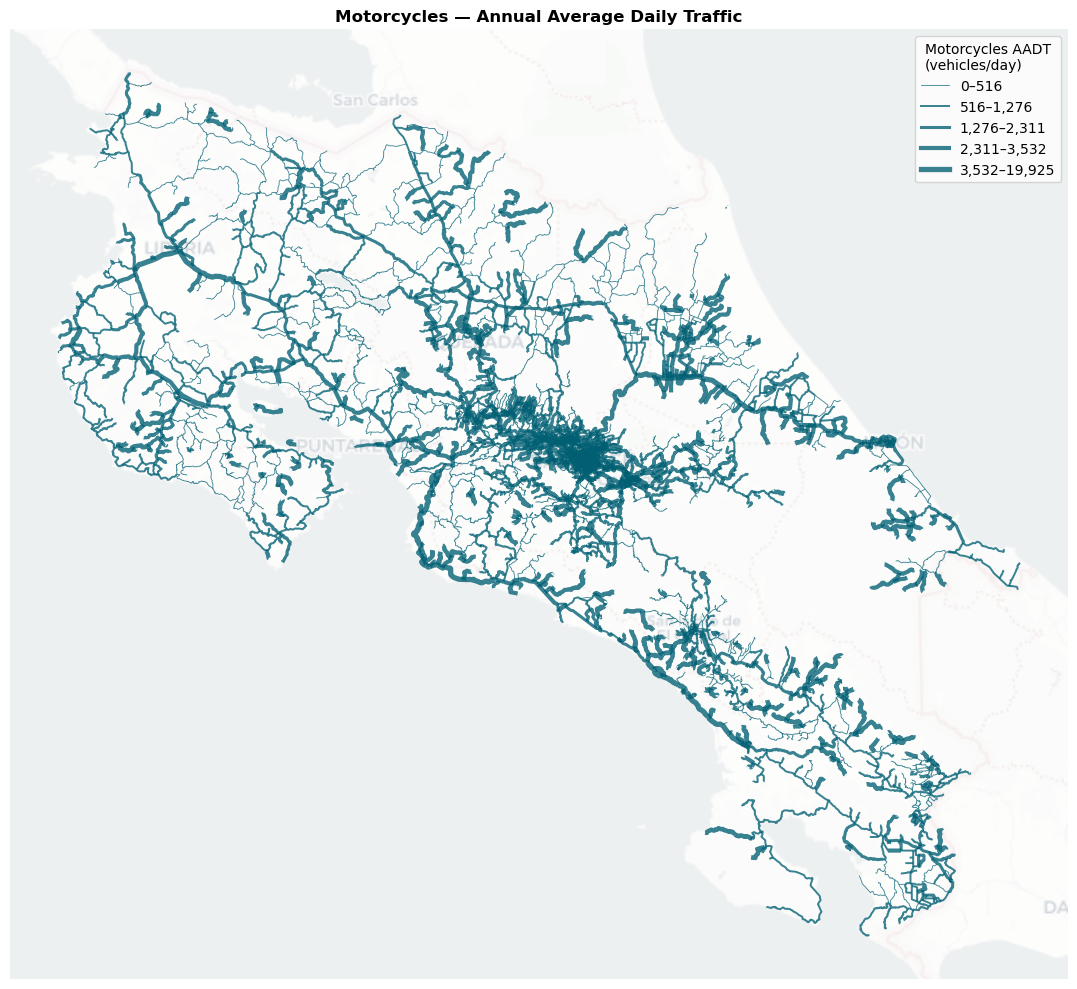

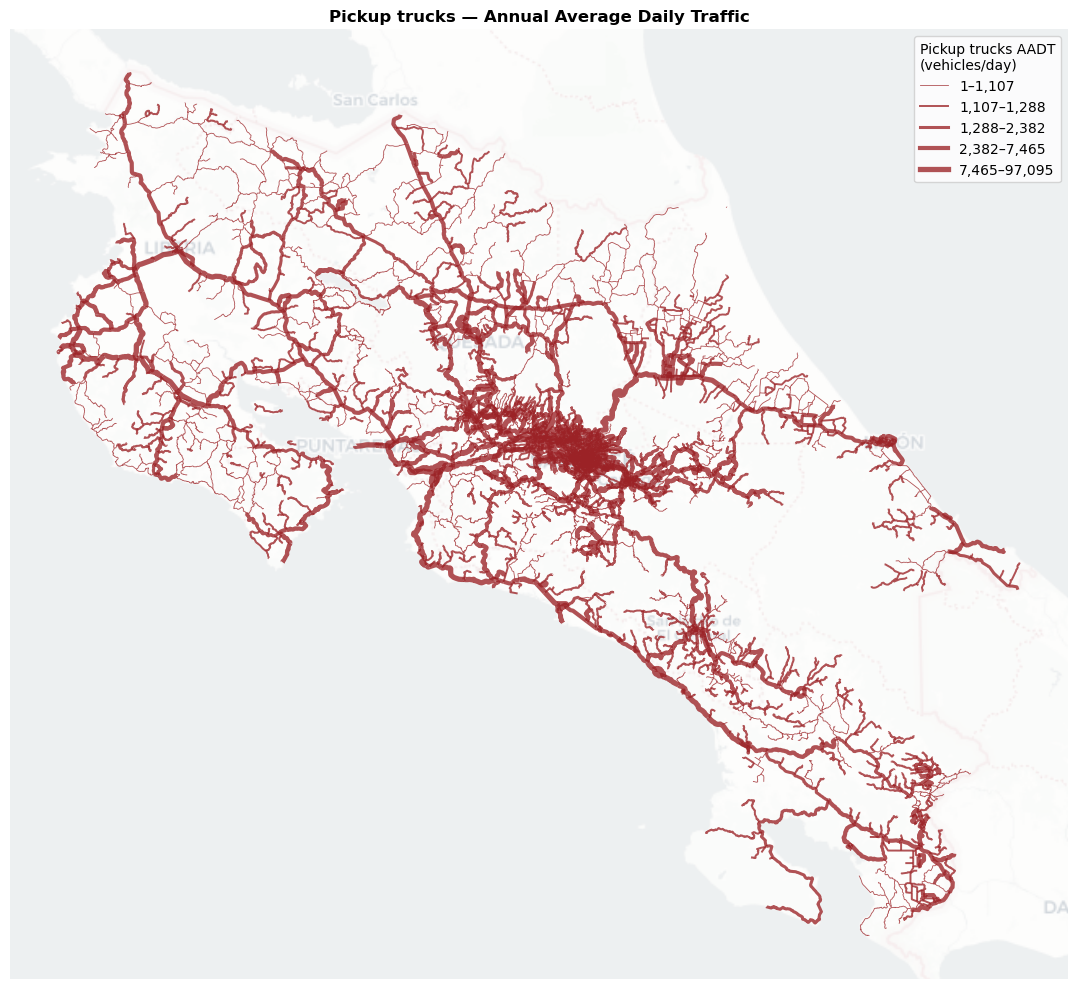

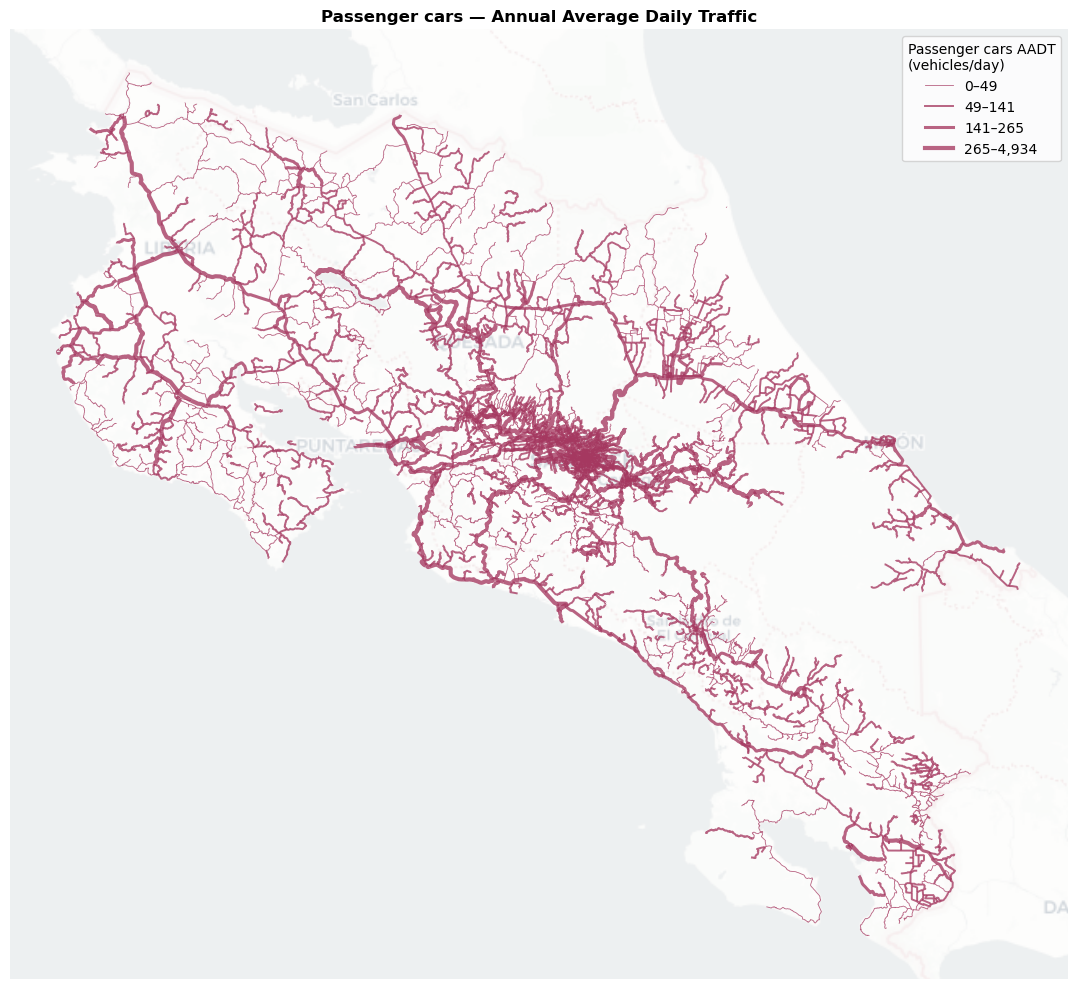

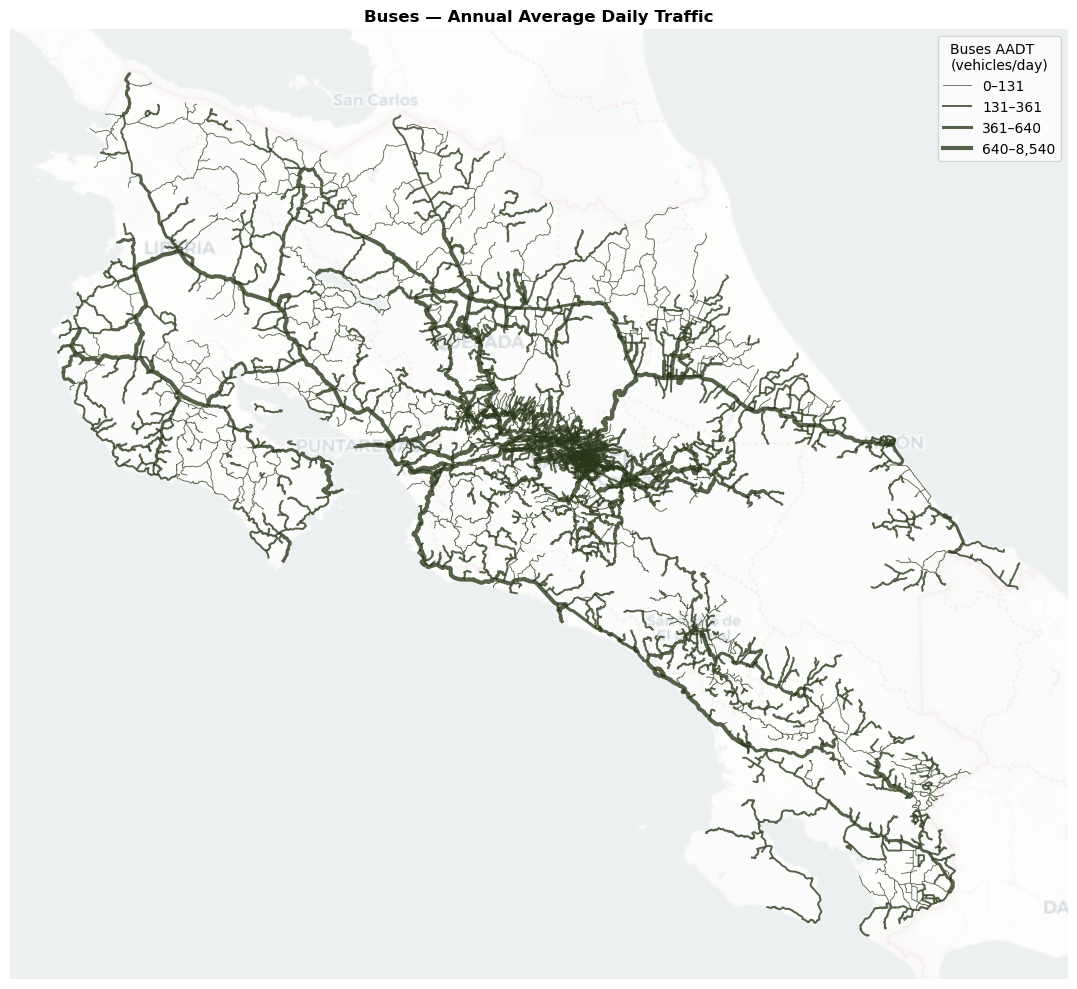

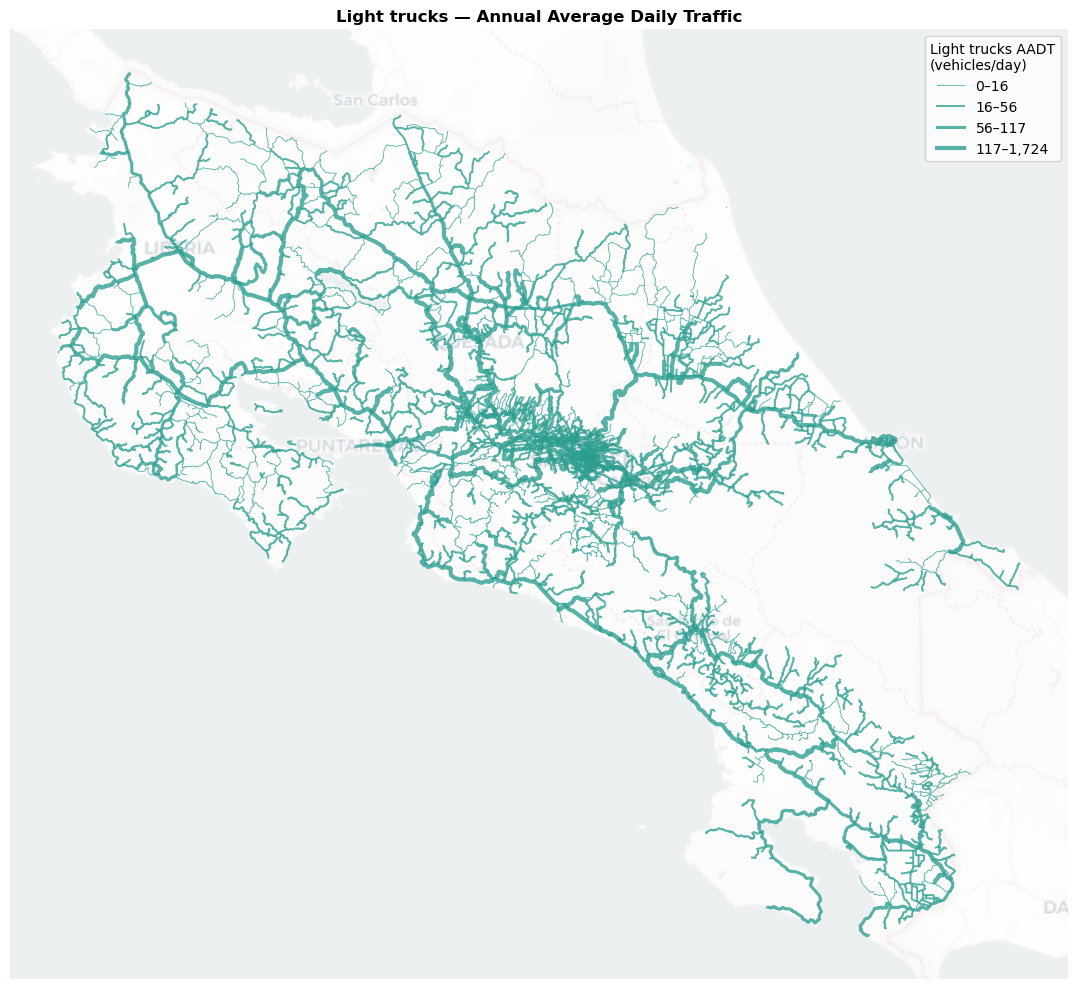

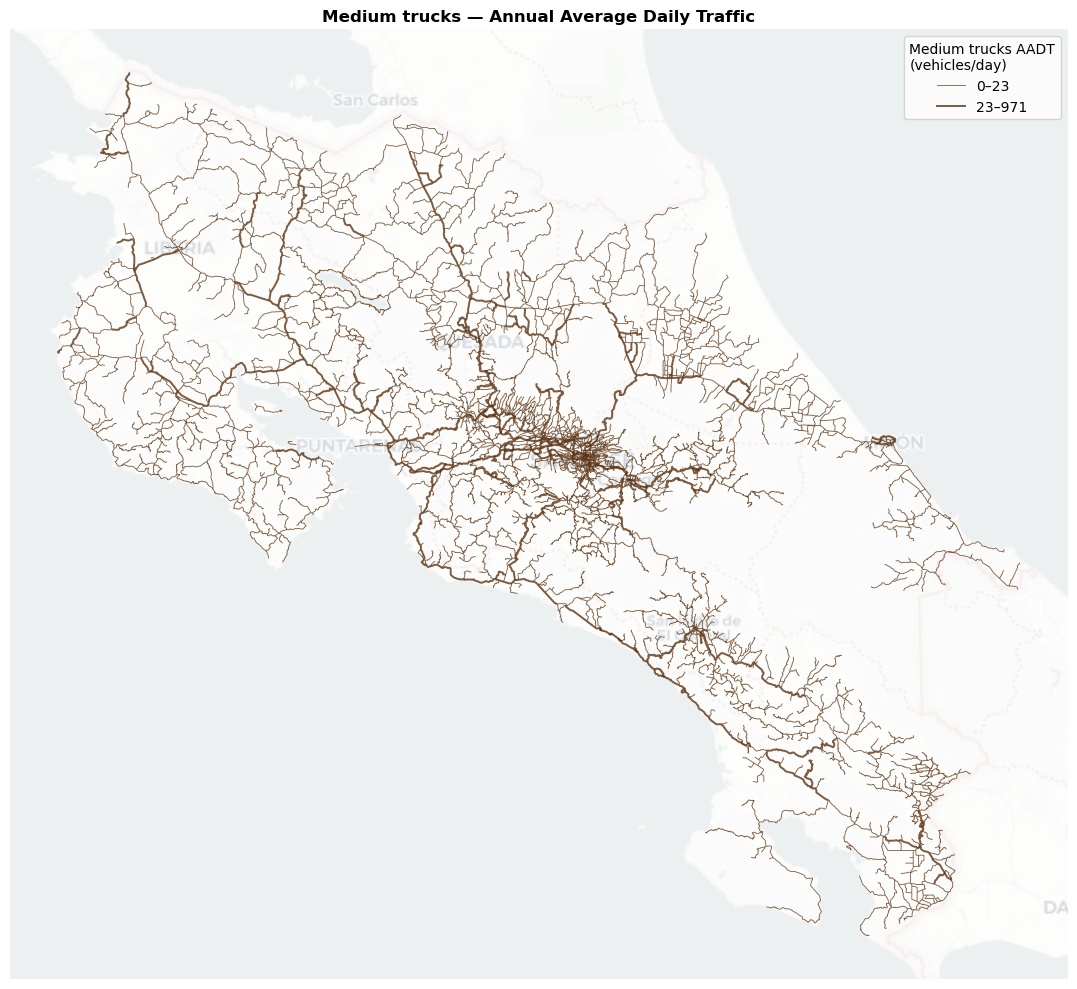

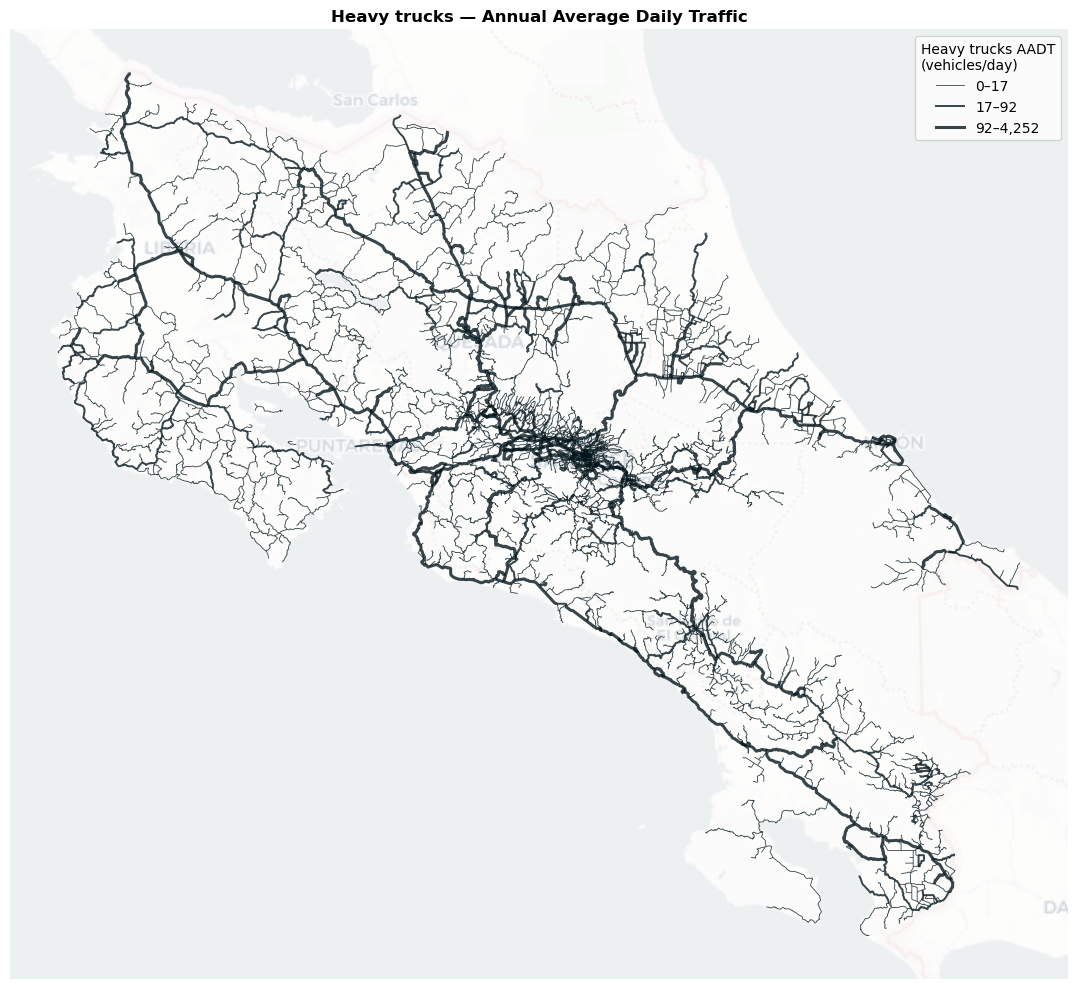

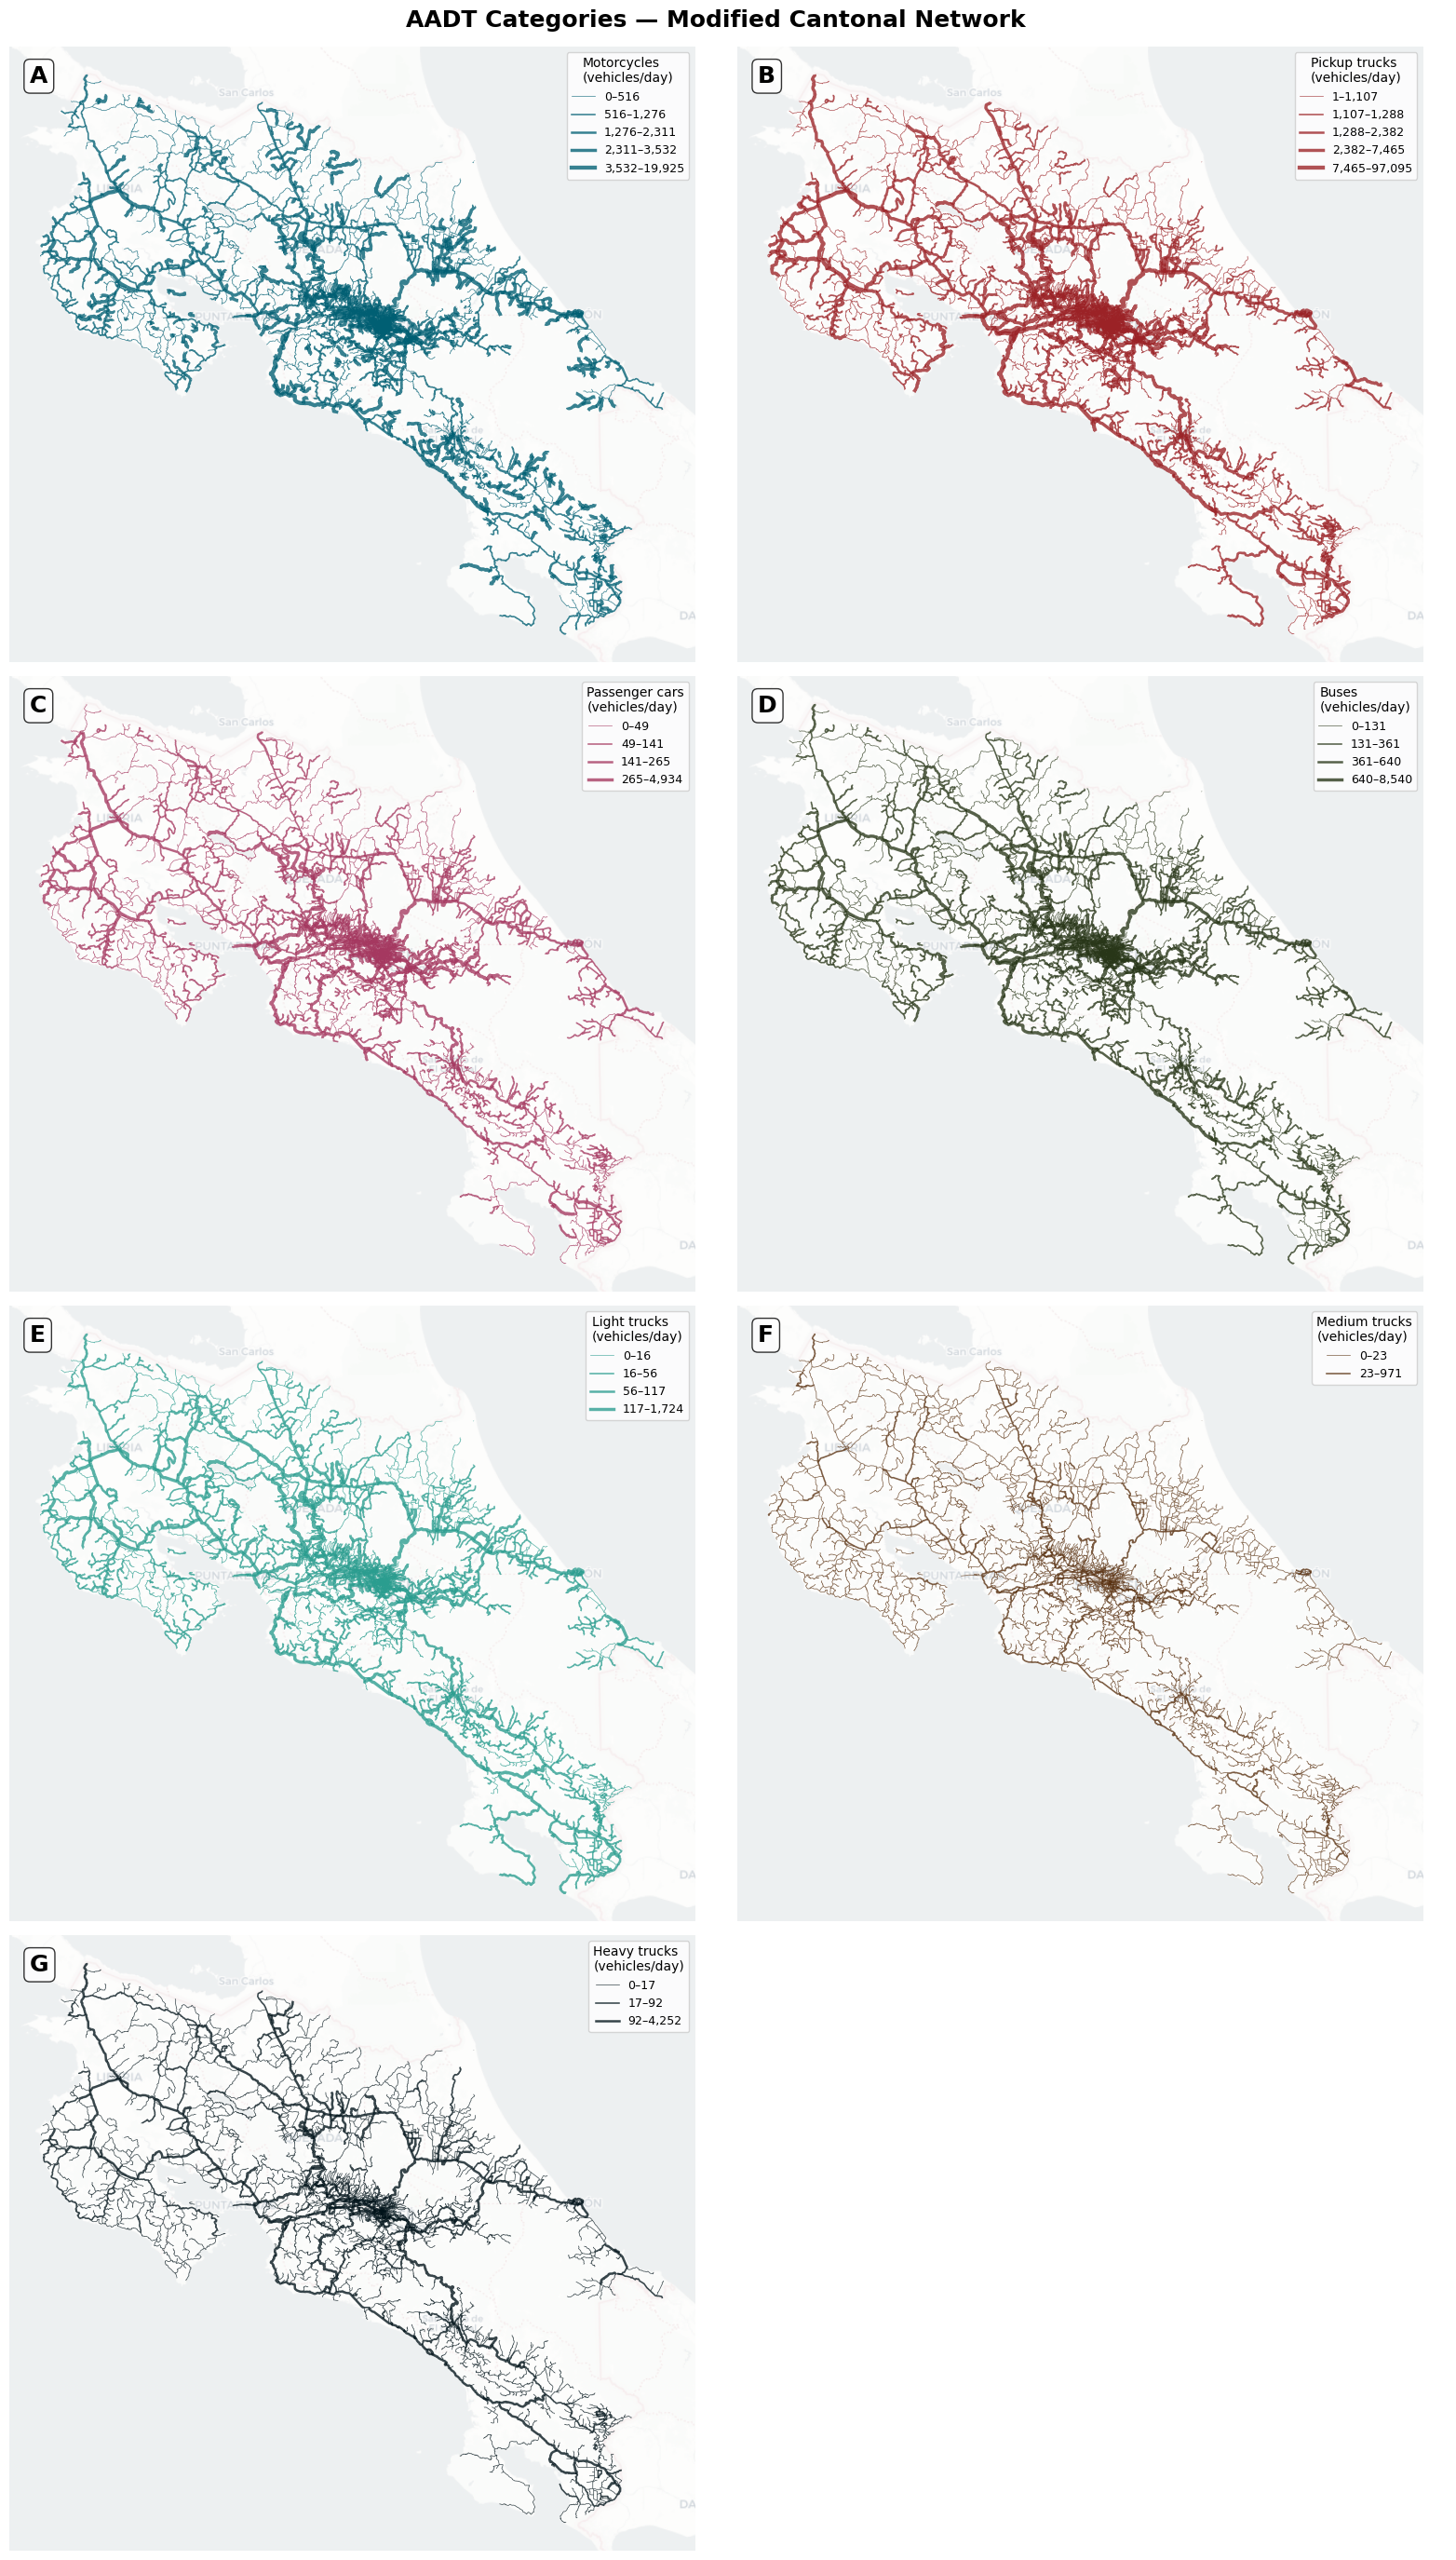

{'motorcycles': [0.0, 516.0, 1275.7000000000007, 2311.0, 3532.0, 19925.0],
 'pickup_trucks': [1.0, 1107.0, 1288.0, 2382.4000000000033, 7465.0, 97095.0],
 'passenger_cars': [0.0, 49.0, 141.0, 265.0, 4934.0],
 'buses': [0.0, 131.0, 361.0, 640.2000000000003, 8540.0],
 'light_trucks': [0.0, 16.0, 56.0, 117.0, 1724.0],
 'medium_trucks': [0.0, 23.0, 971.0],
 'heavy_trucks': [0.0, 17.0, 92.0, 4252.0]}

In [7]:
aadt_breaks = plot_aadt_maps(physical_edges, config, show=True)
aadt_breaks


## 6. Create directed edges

`Unidireccional` roads retain source geometry direction. `Bidireccional` roads—including flagged null-direction fallbacks—receive forward and reverse edges, each with half the two-way AADT.


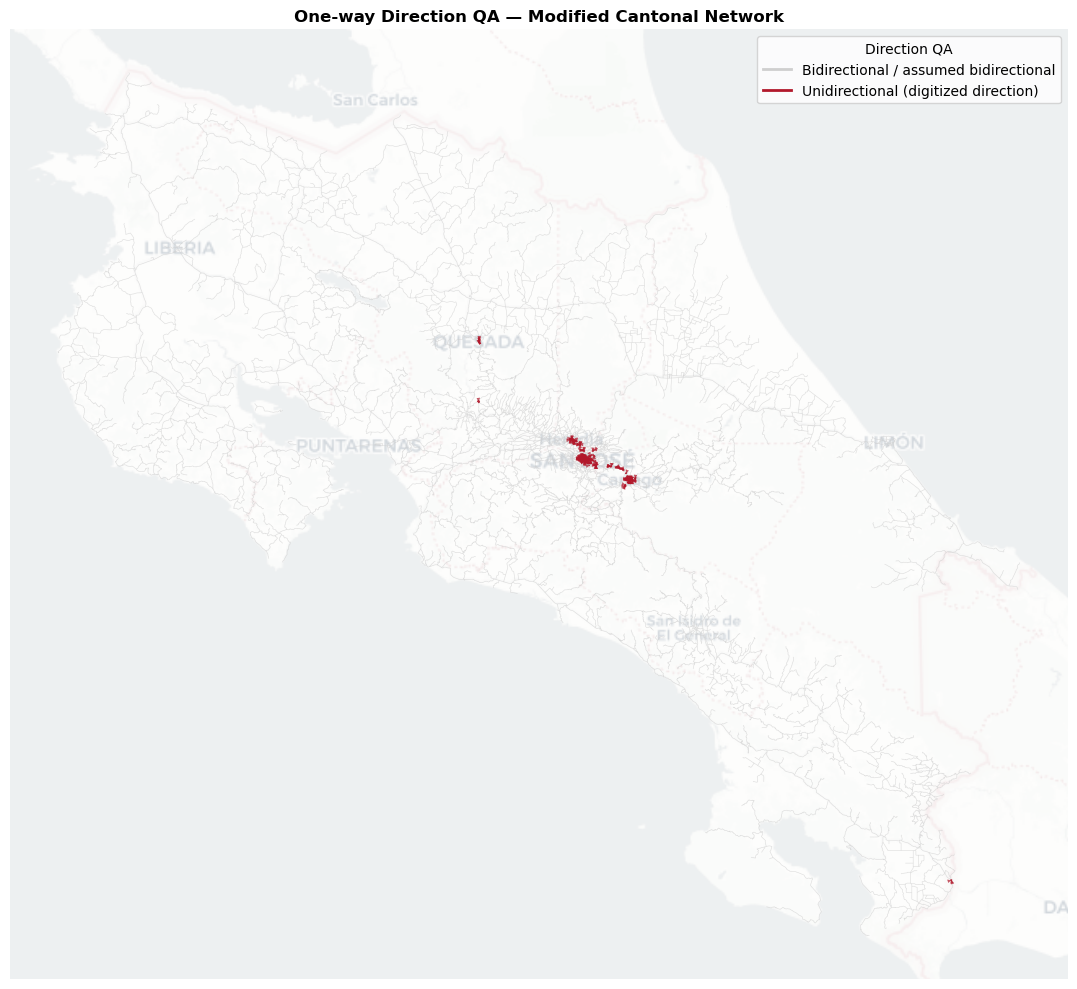

Direction expansion summary
  physical_edges                 : 5,090
  bidirectional_physical_edges   : 4,822
  unidirectional_physical_edges  : 268
  imputed_direction_edges        : 123
  directed_edges                 : 9,912
Direction QA map: /Users/joeldeplaen/Library/CloudStorage/OneDrive-VrijeUniversiteitAmsterdam/Documents/GitHub/Criticality-Analysis-CR/figures/oneway_direction_qa.png


{'physical_edges': 5090,
 'bidirectional_physical_edges': 4822,
 'unidirectional_physical_edges': 268,
 'imputed_direction_edges': 123,
 'directed_edges': 9912}

In [8]:
direction_qa_path = plot_direction_qa(physical_edges, config, show=True)
directed_edges, direction_stats = create_directed_edges(physical_edges)
print(f'Direction QA map: {direction_qa_path}')
direction_stats


## 7. Resolve speed and compute free-flow travel time

Supplied `VEL_KMH` is authoritative. Missing values use the observed median for `CLASE`, then 60 km/h only when no class median is available.


In [9]:
directed_edges, speed_summary = add_speed_and_travel_time(directed_edges, config)
display(speed_summary)
display(directed_edges[['road_length', 'speed', 'fft']].describe())


Resolved speed summary
        speed_source  speed  directed_edges
        class_median   40.0              38
statutory_default_60   60.0             246
            supplied   20.0               4
            supplied   40.0            8757
            supplied   60.0             530
            supplied   80.0             337


,speed_source,speed,directed_edges
0,class_median,40.0,38
1,statutory_default_60,60.0,246
2,supplied,20.0,4
3,supplied,40.0,8757
4,supplied,60.0,530
5,supplied,80.0,337


,road_length,speed,fft
count,9.912000e+03,9912.000000,9.912000e+03
mean,3.031153e+00,42.917676,7.233680e-02
std,3.799231e+00,8.796061,9.282049e-02
min,4.989371e-09,20.000000,1.247343e-10
25%,6.172858e-01,40.000000,1.456531e-02
50%,1.727149e+00,40.000000,4.022561e-02
75%,4.064581e+00,40.000000,9.497688e-02
max,6.061613e+01,80.000000,1.515403e+00


## 8. Extract the strongly connected giant component

Strong connectivity is requested explicitly. Physical length is measured once per `physical_edge_id`, not once per directed copy.


In [10]:
main_network, dropped_roads, giant_stats = extract_strong_giant_component(directed_edges)
giant_stats


Strongly connected giant component
  graph_vertices                 : 4,030
  strong_components              : 52
  giant_vertices                 : 3,909
  directed_edges_total           : 9,912
  directed_edges_kept            : 9,764
  directed_edges_dropped         : 148
  directed_length_fraction       : 98.28%
  physical_length_total_km       : 15,069.90
  physical_length_kept_km        : 14,810.54
  physical_length_fraction       : 98.28%


{'graph_vertices': 4030,
 'strong_components': 52,
 'giant_vertices': 3909,
 'directed_edges_total': 9912,
 'directed_edges_kept': 9764,
 'directed_edges_dropped': 148,
 'directed_length_fraction': 0.9828069146414379,
 'physical_length_total_km': 15069.904093225949,
 'physical_length_kept_km': 14810.544390949071,
 'physical_length_fraction': 0.9827895585351826}

## 9. Save and verify GeoPackages

Dropped-road diagnostics are written before the 95% assertion. A passing main network is reopened and checked for row count, CRS, unique IDs, required fields, and null critical values.


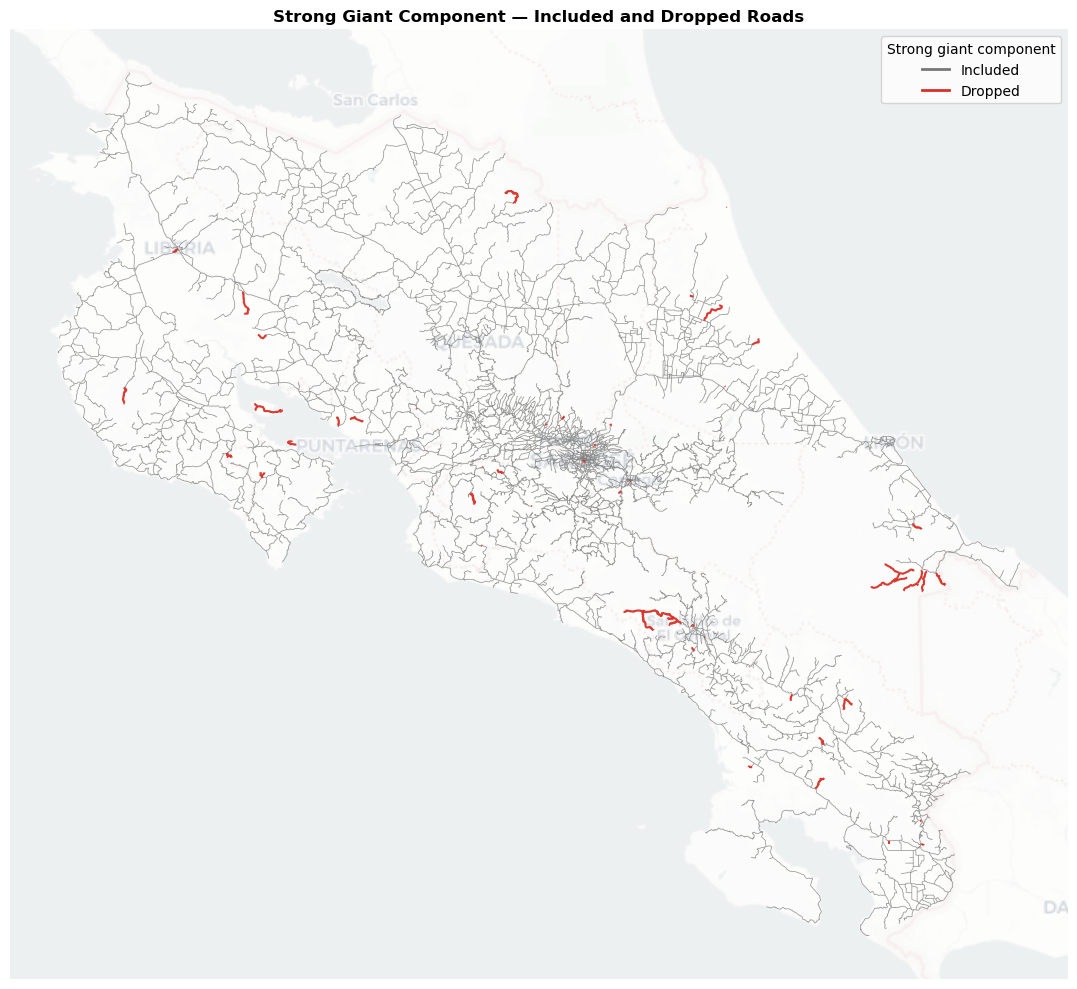

Saved dropped-road diagnostics: /Users/joeldeplaen/Library/CloudStorage/OneDrive-VrijeUniversiteitAmsterdam/Documents/GitHub/Criticality-Analysis-CR/intermediate_results/gpkg/network/giant_component_dropped_roads.gpkg
Output manifest
                       output                                                                                                                                                                                      path                         layer  rows       crs  size_bytes
        main_network_directed         /Users/joeldeplaen/Library/CloudStorage/OneDrive-VrijeUniversiteitAmsterdam/Documents/GitHub/Criticality-Analysis-CR/intermediate_results/gpkg/network/main_network_directed.gpkg         main_network_directed  9764 EPSG:8908    92913664
giant_component_dropped_roads /Users/joeldeplaen/Library/CloudStorage/OneDrive-VrijeUniversiteitAmsterdam/Documents/GitHub/Criticality-Analysis-CR/intermediate_results/gpkg/network/giant_component_dropped_roads.gpkg gi

,output,path,layer,rows,crs,size_bytes
0,main_network_directed,/Users/joeldeplaen/Library/CloudStorage/OneDri...,main_network_directed,9764,EPSG:8908,92913664
1,giant_component_dropped_roads,/Users/joeldeplaen/Library/CloudStorage/OneDri...,giant_component_dropped_roads,148,EPSG:8908,2678784


In [11]:
output_manifest = save_outputs(
    directed_edges,
    main_network,
    dropped_roads,
    giant_stats,
    config,
    show=True,
)
display(output_manifest)


## Downstream compatibility

The CR output intentionally retains motorcycles and pickups and does not invent an articulated-vehicle category. Serbia-oriented criticality formulas and path configuration must be adapted separately before consuming this GeoPackage.
